# 05 · Radiation models: dose budget and solar-storm alarm

**Questions**
1. **Dose counter:** how fast does the dose budget fill in three settings (ISS, Mars transit, Mars surface)?
2. **Storm (SPE) alarm:** which detector catches the 20 May 2024 storm soonest without false shelter alarms in the quiet months?
3. Does removing the diurnal cycle help? Does the slow solar-cycle drift cause alarms?

**Candidates for the alarm:** A robust z of the hourly dose rate vs the trailing 7-day median (team's plan) · B ratio to the 7-day median ·
C CUSUM on log dose rate · D EWMA on log dose rate · E change point (PELT).

**Inputs:** `data/processed/msl_rad_hourly.parquet`, `msl_rad_daily.parquet` (real, notebook 04); `data/raw/osdr_eda/*_radiation.csv` (real ISS dose);
the transit rate 1.84 mSv/day is a published constant (Zeitlin et al. 2013), not a measurement series.
**Outputs:** comparison table, figures `reports/figures/05_*.png`, radiation parameters in `models/engine_config.json`.

In [1]:
import sys
sys.path.insert(0, "../ml")
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import Parallel, delayed
from sol_ml.nbutil import *
from sol_ml.detectors import radiation as rad

rng = setup()
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore")
DEPS = ["detectors/radiation.py", "detectors/univariate.py"]
Q = rad.QUALITY_FACTOR                 # 3.0, Hassler et al. 2014
BUDGET_MSV = 600.0                     # NASA-STD-3001 career limit, the budget already used by the v0 engine
TRANSIT_MSV_PER_DAY = 1.84             # Zeitlin et al. 2013, Earth-Mars cruise

hourly = pd.read_parquet(PROCESSED / "msl_rad_hourly.parquet").set_index("hour")
daily = pd.read_parquet(PROCESSED / "msl_rad_daily.parquet").set_index("date")
x, local_hour, T = hourly.dose_e.to_numpy(float), hourly.local_hour.to_numpy(float), hourly.index
months = np.isfinite(x).sum() / 720
print(len(x), "hours,", round(months, 1), "months of data")

25097 hours, 34.7 months of data


## 1. Cumulative dose counter
Deterministic: absorbed dose (Gy) × quality factor Q = dose equivalent (Sv). YELLOW at 80 % of the budget, RED at 100 %.

In [2]:
iss = pd.concat([pd.read_csv(f, parse_dates=["time"]).assign(mission=f.name.split("_")[0])
                 for f in sorted((RAW / "osdr_eda").glob("*_radiation.csv"))], ignore_index=True)
iss_rate_mgy = iss.groupby("mission").total.median()
print("ISS total dose rate per mission (mGy/day, real OSDR EDA):", iss_rate_mgy.round(3).to_dict())

mars_msv = rad.cumulative_dose_msv(daily.dose_e.to_numpy(), Q)
rates = pd.DataFrame({
    "absorbed dose (mGy/day)": [iss.total.median(), np.nan, daily.dose_e.median() / 1000],
    "dose equivalent (mSv/day)": [iss.total.median() * Q, TRANSIT_MSV_PER_DAY, mars_msv[-1] / len(daily)],
    "source": ["OSDR EDA, real ISS dosimetry x Q", "Zeitlin et al. 2013 (constant)", "MSL RAD detector E, real x Q"]},
    index=["ISS", "Mars transit", "Mars surface"])
rates["days to YELLOW (80 %)"] = (0.8 * BUDGET_MSV / rates["dose equivalent (mSv/day)"]).round(0)
rates["days to RED (100 %)"] = (BUDGET_MSV / rates["dose equivalent (mSv/day)"]).round(0)
rates.round(3)

ISS total dose rate per mission (mGy/day, real OSDR EDA): {'RR-1': 0.203, 'RR-12': 0.358, 'RR-17': 0.321, 'RR-19': 0.363, 'RR-23': 0.352, 'RR-3': 0.227, 'RR-4': 0.24, 'RR-6': 0.283, 'RR-7': 0.28, 'RR-8': 0.285, 'RR-9': 0.313}


,absorbed dose (mGy/day),dose equivalent (mSv/day),source,days to YELLOW (80 %),days to RED (100 %)
ISS,0.292,0.875,"OSDR EDA, real ISS dosimetry x Q",549.0,686.0
Mars transit,NaN,1.840,Zeitlin et al. 2013 (constant),261.0,326.0
Mars surface,0.160,0.492,"MSL RAD detector E, real x Q",976.0,1221.0


Mars mission total: 908 mSv = 151 % of the budget -> RED
mission day of YELLOW / RED: {'YELLOW': 483, 'RED': 693}
the May 2024 storm added 5.2 mSv on the surface (0.9 % of the budget, 11 quiet days' worth)


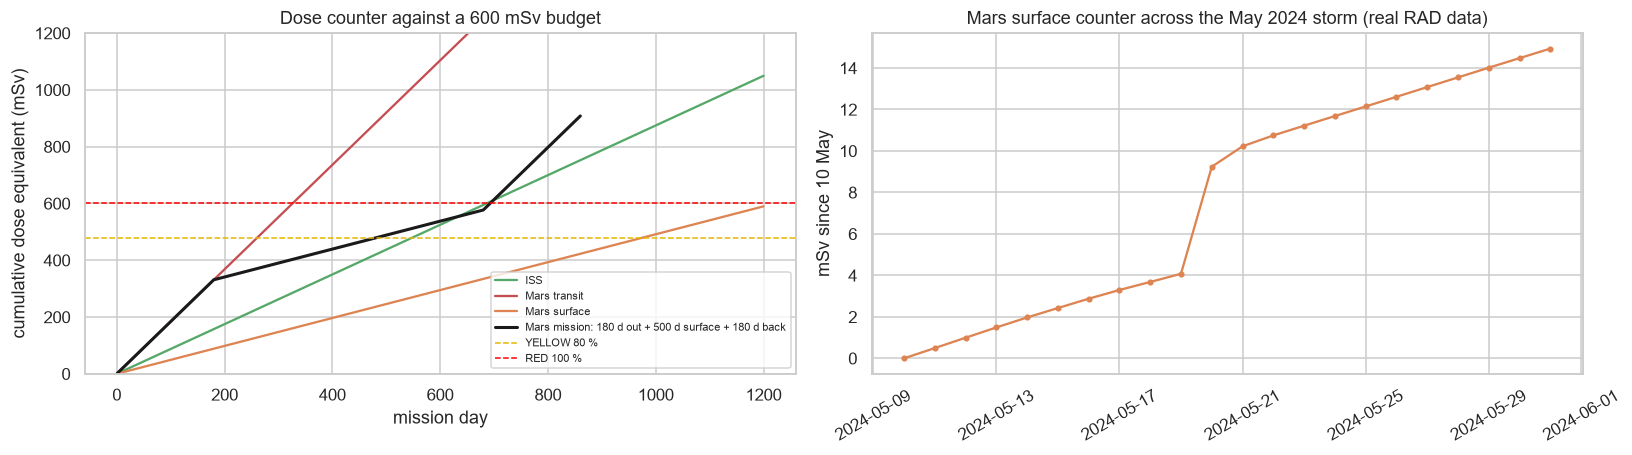

In [3]:
days = np.arange(1, 1201)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
for name, color in zip(rates.index, ["#55a868", "#c44e52", "#dd8452"]):
    axes[0].plot(days, days * rates.loc[name, "dose equivalent (mSv/day)"], label=name, color=color)
transit, stay = 180, 500
mission = np.concatenate([np.full(transit, TRANSIT_MSV_PER_DAY), np.full(stay, rates.loc["Mars surface", "dose equivalent (mSv/day)"]),
                          np.full(transit, TRANSIT_MSV_PER_DAY)]).cumsum()
axes[0].plot(np.arange(1, len(mission) + 1), mission, color="k", lw=2, label=f"Mars mission: {transit} d out + {stay} d surface + {transit} d back")
for share, color, label in ((0.8, "#e6b800", "YELLOW 80 %"), (1.0, "red", "RED 100 %")):
    axes[0].axhline(share * BUDGET_MSV, color=color, ls="--", lw=1, label=label)
axes[0].set(xlabel="mission day", ylabel="cumulative dose equivalent (mSv)", ylim=(0, 1200), title=f"Dose counter against a {BUDGET_MSV:.0f} mSv budget")
axes[0].legend(fontsize=7)
storm_days = slice("2024-05-10", "2024-05-31")
cum = pd.Series(mars_msv, index=daily.index)
axes[1].plot(cum.loc[storm_days].index, cum.loc[storm_days] - cum.loc["2024-05-10"], marker="o", ms=3, color="#dd8452")
axes[1].set(title="Mars surface counter across the May 2024 storm (real RAD data)", ylabel="mSv since 10 May")
axes[1].tick_params(axis="x", rotation=30)
savefig("05_dose_counter");
storm_msv = (daily.dose_e.loc["2024-05-20":"2024-05-21"] - daily.dose_e.loc["2024-05-10":"2024-05-19"].median()).sum() * Q / 1000
status_day = {s: int(np.argmax(mission >= share * BUDGET_MSV)) + 1 if (mission >= share * BUDGET_MSV).any() else None
              for s, share in (("YELLOW", 0.8), ("RED", 1.0))}
print("Mars mission total: %.0f mSv = %.0f %% of the budget -> %s" % (mission[-1], 100 * mission[-1] / BUDGET_MSV, rad.dose_status(mission[-1], BUDGET_MSV)))
print("mission day of YELLOW / RED:", status_day)
print("the May 2024 storm added %.1f mSv on the surface (%.1f %% of the budget, %.0f quiet days' worth)" % (
    storm_msv, 100 * storm_msv / BUDGET_MSV, storm_msv / rates.loc["Mars surface", "dose equivalent (mSv/day)"]))

## 2. The diurnal cycle: what does removing it change?

quiet-hour SD around the baseline: raw 3.16 %, after removing the diurnal cycle 3.17 %


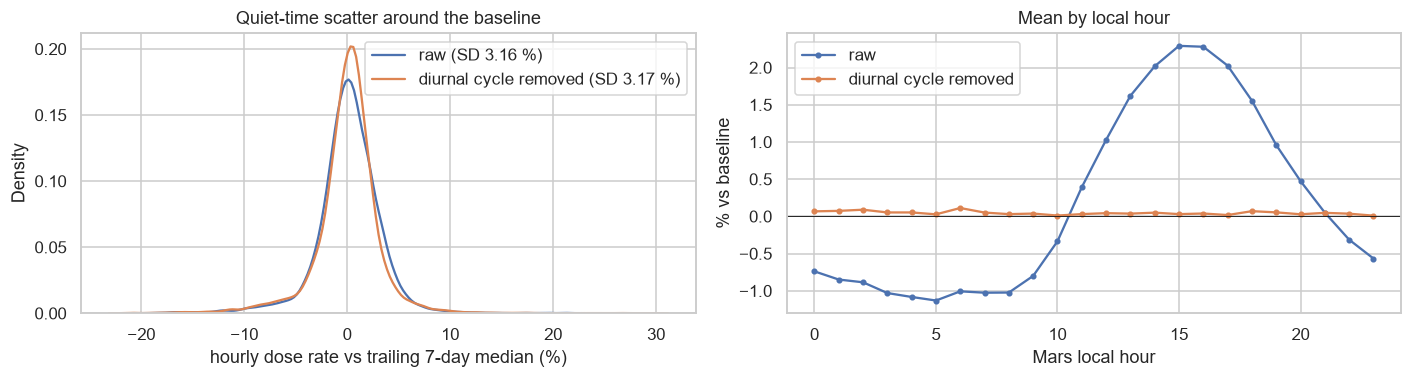

In [4]:
x_flat = rad.deseasonalize(x, local_hour)
def rel_noise(v):
    med, _ = rad.trailing_baseline(v)
    r = v / med
    return r[(r > 0.7) & (r < 1.3)]
before, after = rel_noise(x), rel_noise(x_flat)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for v, label in ((before, "raw"), (after, "diurnal cycle removed")):
    sns.kdeplot(100 * (v - 1), ax=axes[0], label=f"{label} (SD {100 * np.nanstd(v):.2f} %)")
axes[0].set(xlabel="hourly dose rate vs trailing 7-day median (%)", title="Quiet-time scatter around the baseline"); axes[0].legend()
prof = pd.DataFrame({"raw": x / rad.trailing_baseline(x)[0], "removed": x_flat / rad.trailing_baseline(x_flat)[0], "h": np.floor(local_hour)})
prof = prof[(prof.raw > 0.7) & (prof.raw < 1.3)].groupby("h").mean()
axes[1].plot(prof.index, 100 * (prof.raw - 1), marker="o", ms=3, label="raw")
axes[1].plot(prof.index, 100 * (prof.removed - 1), marker="o", ms=3, label="diurnal cycle removed")
axes[1].axhline(0, color="k", lw=0.6)
axes[1].set(xlabel="Mars local hour", ylabel="% vs baseline", title="Mean by local hour"); axes[1].legend()
savefig("05_diurnal_effect");
print("quiet-hour SD around the baseline: raw %.2f %%, after removing the diurnal cycle %.2f %%" % (100 * np.nanstd(before), 100 * np.nanstd(after)))

## 3. Storm alarm: set-up
- **Must catch:** the 20 May 2024 storm. Its *onset* is the first hour above twice the trailing median; delays are counted from that hour.
- **False shelter alarms:** alert events anywhere else in the record (alert hours less than 24 h apart are one event). The record also holds
  smaller real events (notebook 04), so each event is checked against RAD's **second, independent detector** (B, silicon): if B is also at least 20 % above
  its own baseline within 3 hours, the event is a real rise in radiation, not noise in E. Only the *unconfirmed* events count as false alarms.
- **Sensitivity:** the May 2024 storm shape is scaled down and planted at 100 random quiet hours, at peak sizes of 1.5×, 2×, 3× and 5× the quiet level.
  Caught = a new alert within 24 hours.

In [5]:
i0, i1 = T.get_loc(pd.Timestamp("2024-05-19 00:00")), T.get_loc(pd.Timestamp("2024-05-23 00:00"))
onset = rad.onset_hour(x, i0, i1)
base = np.nanmedian(x[onset - 168: onset])
last_high = onset + int(np.flatnonzero(x[onset: i1] > 2 * base).max())
excluded = np.zeros(len(x), bool)
excluded[onset - 24: last_high + 48] = True
print("onset:", T[onset], "| quiet level before:", round(base, 1), "| peak hour:", T[int(np.nanargmax(x))], "| above 2x until", T[last_high])

level = daily.dose_e.rolling(27, min_periods=10).median().shift(1)
event_days = set(daily.index[(daily.dose_e_max / level) >= 1.5])
day_of = T.normalize()
b_ratio = np.nan_to_num(rad.spe_score(hourly.dose_b_rtg.to_numpy(float), "ratio"), nan=1.0)      # independent silicon detector
CONFIRM = 1.2
def confirmed_by_b(start):
    return bool(b_ratio[max(start - 3, 0): start + 4].max() >= CONFIRM)

profile = np.nan_to_num(x[onset - 2: onset + 60] - base, nan=0.0).clip(min=0)        # the storm's excess over the quiet level
PEAKS = (1.5, 2.0, 3.0, 5.0)
PRE, POST = 400, 72
quiet_ok = np.array([d not in event_days for d in day_of])
candidates = [t for t in range(PRE + 200, len(x) - POST) if quiet_ok[t - 120: t + 120].all() and not excluded[t - 240: t + 240].any()
              and np.isfinite(x[t - PRE: t + POST]).mean() > 0.97]
SITES = sorted(rng.choice(candidates, 100, replace=False).tolist())
print(len(candidates), "quiet candidate hours ->", len(SITES), "planted storms per size")

def planted(t, peak):
    """slice of the hourly series around t with a scaled storm added, plus its local hours"""
    seg = x[t - PRE: t + POST].copy()
    scale = (peak - 1) * np.nanmedian(seg[:PRE]) / profile.max()
    seg[PRE - 2: PRE - 2 + len(profile)] += scale * profile
    return seg, local_hour[t - PRE: t + POST]

onset: 2024-05-20 05:00:00 | quiet level before: 147.9 | peak hour: 2024-05-20 06:00:00 | above 2x until 2024-05-21 12:00:00


20707 quiet candidate hours -> 100 planted storms per size


In [6]:
GRID = {"robust_z": (4, 5, 6, 8, 10, 15, 20, 30), "ratio": (1.15, 1.2, 1.3, 1.5, 2.0, 3.0), "cusum": (10, 20, 40, 80, 160, 320),
        "ewma": (3, 4, 5, 6, 8, 10, 15), "changepoint": (4, 6, 8, 12, 20)}
LETTER = {"robust_z": "A robust z", "ratio": "B ratio", "cusum": "C CUSUM (log)", "ewma": "D EWMA (log)", "changepoint": "E change point"}
PREFILTER = 1.15           # E runs PELT only in hours that are already 15 % above the baseline (it is too slow to run every hour)

def cp_scores(v):
    ratio = rad.spe_score(v, "ratio")
    hours = np.flatnonzero(np.nan_to_num(ratio) > PREFILTER)
    out = np.zeros(len(v))
    out[hours] = [rad.changepoint_score(v, int(t)) for t in hours]
    return out

def scores_for(v, lh, deseason):
    v = rad.deseasonalize(v, lh) if deseason else v
    out = {m: rad.spe_score(v, m) for m in rad.METHODS}
    out["changepoint"] = cp_scores(v)
    return out

def site_scores(t, peak, deseason):
    seg, lh = planted(t, peak)
    clean = scores_for(x[t - PRE: t + POST], lh, deseason)
    new = scores_for(seg, lh, deseason)
    return {m: (clean[m][PRE - 2:], new[m][PRE - 2:]) for m in new}          # from 2 h before the planted onset

def compute():
    rows = []
    for deseason in (False, True):
        full = scores_for(x, local_hour, deseason)
        site = {peak: Parallel(n_jobs=-1)(delayed(site_scores)(t, peak, deseason) for t in SITES) for peak in PEAKS}
        for method, thresholds in GRID.items():
            for thr in thresholds:
                for hold in (1, 2):
                    alert = rad.persistent(np.nan_to_num(full[method], nan=-np.inf) > thr, hold)
                    hit = np.flatnonzero(alert[onset - 24: onset + 48])
                    outside = alert & ~excluded
                    hours = np.flatnonzero(outside)
                    starts = hours[np.concatenate([[True], np.diff(hours) > 24])] if len(hours) else hours
                    row = {"method": method, "deseasonalized": deseason, "thr": thr, "hold_hours": hold,
                           "may2024_delay_h": float(hit[0] - 24) if len(hit) else np.nan,
                           "false_events": len(starts), "confirmed_by_detector_b": int(sum(confirmed_by_b(int(s)) for s in starts))}
                    for peak in PEAKS:
                        delays = []
                        for clean_s, new_s in (s[method] for s in site[peak]):
                            a_new = rad.persistent(np.nan_to_num(new_s, nan=-np.inf) > thr, hold)
                            a_old = rad.persistent(np.nan_to_num(clean_s, nan=-np.inf) > thr, hold)
                            fresh = np.flatnonzero((a_new & ~a_old)[:26])
                            delays.append(fresh[0] - 2 if len(fresh) else np.nan)
                        row[f"caught_{peak:g}x"] = float(np.mean(~np.isnan(delays)))
                        row[f"delay_{peak:g}x_h"] = float(np.nanmedian(delays)) if not np.all(np.isnan(delays)) else np.nan
                    rows.append(row)
    return pd.DataFrame(rows)

res = cached("nb05_spe", [SITES, GRID, PEAKS, PREFILTER, CONFIRM, "v2"], compute, deps=DEPS)
res = res.rename(columns={"false_events": "other_events"})
res["false_alarms"] = res.other_events - res.confirmed_by_detector_b
res["false_per_year"] = res.false_alarms / months * 12
res["model"] = res.method.map(LETTER)
print(len(res), "configurations")
res.groupby(["model", "deseasonalized"]).agg(configs=("thr", "size"), catch_may2024=("may2024_delay_h", lambda s: int(s.notna().sum())),
                                              min_false=("false_alarms", "min"), max_false=("false_alarms", "max"))

128 configurations


configs  catch_may2024  min_false  max_false
model          deseasonalized                                              
A robust z     False                16             16          0          9
               True                 16             16          0         12
B ratio        False                12             12          0          0
               True                 12             12          0          1
C CUSUM (log)  False                12             12          1         54
               True                 12             12          1         54
D EWMA (log)   False                14             14          0          5
               True                 14             14          0          8
E change point False                10             10          0          0
               True                 10             10          0          0

## 4. Comparison
Selection rule: the detector must catch 20 May 2024 and raise **no more than one false shelter alarm per year**; among those, the most sensitive
setting wins (smallest storm it still catches, then the shortest delay). The team can change the false-alarm limit; the full table is kept.

In [7]:
MAX_FALSE_PER_YEAR = 1.0
ok = res[res.may2024_delay_h.notna() & (res.false_per_year <= MAX_FALSE_PER_YEAR)].copy()
ok["sensitivity"] = ok[[f"caught_{p:g}x" for p in PEAKS]].sum(axis=1)
SORT = ["sensitivity", "may2024_delay_h", "false_alarms", "other_events", "deseasonalized", "hold_hours"]
ASC = [False, True, True, True, True, True]
best = ok.sort_values(SORT, ascending=ASC).groupby(["model", "deseasonalized"]).head(1)
show = ["model", "deseasonalized", "thr", "hold_hours", "may2024_delay_h", "other_events", "confirmed_by_detector_b", "false_alarms"] + \
       [f"caught_{p:g}x" for p in PEAKS] + ["delay_2x_h", "delay_5x_h"]
best = best.sort_values(SORT, ascending=ASC)[show].reset_index(drop=True)
print(f"Best setting per model with at most {MAX_FALSE_PER_YEAR:g} false shelter alarm per year over {months:.0f} months.")
print("may2024_delay_h: hours from the 2x onset to the alert (0 = same hour, negative = earlier).")
print("other_events: alarm events apart from May 2024; confirmed_by_detector_b: of those, real rises also seen by the silicon detector; false_alarms: the rest.")
best.round(2)

Best setting per model with at most 1 false shelter alarm per year over 35 months.
may2024_delay_h: hours from the 2x onset to the alert (0 = same hour, negative = earlier).
other_events: alarm events apart from May 2024; confirmed_by_detector_b: of those, real rises also seen by the silicon detector; false_alarms: the rest.


,model,deseasonalized,thr,hold_hours,may2024_delay_h,other_events,confirmed_by_detector_b,false_alarms,caught_1.5x,caught_2x,caught_3x,caught_5x,delay_2x_h,delay_5x_h
0,B ratio,False,1.3,1,0.0,6,6,0,1.00,1.00,1.00,1.00,0.0,0.0
1,E change point,False,20.0,1,0.0,6,6,0,1.00,1.00,1.00,1.00,0.0,0.0
2,B ratio,True,1.3,1,0.0,6,6,0,1.00,1.00,1.00,1.00,0.0,0.0
3,E change point,True,20.0,1,0.0,6,6,0,1.00,1.00,1.00,1.00,1.0,0.0
4,A robust z,False,6.0,1,0.0,11,11,0,1.00,1.00,1.00,1.00,0.0,0.0
5,A robust z,True,6.0,1,0.0,12,11,1,1.00,1.00,1.00,1.00,0.0,0.0
6,D EWMA (log),False,3.0,2,1.0,13,11,2,0.99,1.00,1.00,1.00,1.0,1.0
7,D EWMA (log),True,4.0,1,0.0,10,10,0,0.97,1.00,1.00,1.00,0.0,0.0
8,C CUSUM (log),True,160.0,1,7.0,5,4,1,0.47,0.79,0.94,0.97,4.0,1.0
9,C CUSUM (log),False,160.0,1,7.0,5,4,1,0.09,0.76,0.94,0.98,7.0,2.0


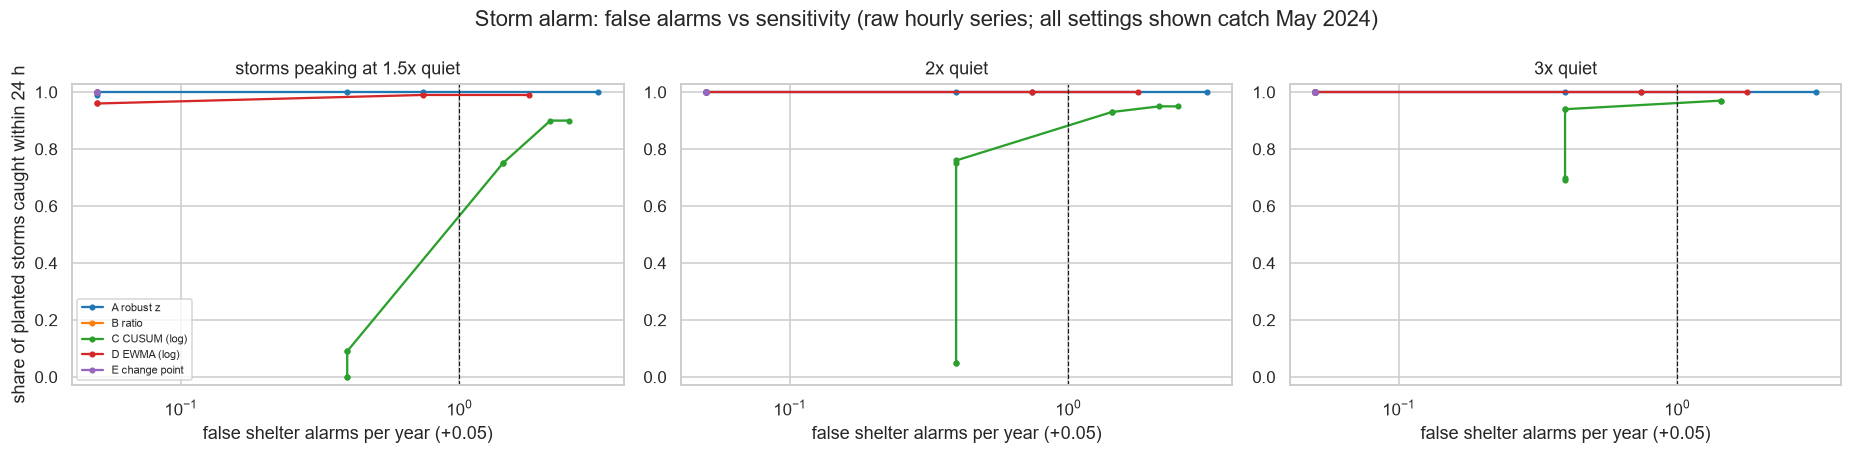

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
palette = dict(zip(LETTER.values(), sns.color_palette("tab10", 5)))
raw = res[~res.deseasonalized]
for ax, col, title in zip(axes, ["caught_1.5x", "caught_2x", "caught_3x"], ["storms peaking at 1.5x quiet", "2x quiet", "3x quiet"]):
    for model, g in raw[raw.may2024_delay_h.notna()].groupby("model"):
        g = g.sort_values("false_per_year")
        f = g[g[col] >= g[col].cummax()]
        ax.plot(f.false_per_year + 0.05, f[col], marker="o", ms=3, color=palette[model], label=model)
    ax.axvline(MAX_FALSE_PER_YEAR, color="k", ls="--", lw=0.8)
    ax.set(xscale="log", xlabel="false shelter alarms per year (+0.05)", title=title, ylim=(-0.03, 1.03))
axes[0].set_ylabel("share of planted storms caught within 24 h"); axes[0].legend(fontsize=7)
fig.suptitle("Storm alarm: false alarms vs sensitivity (raw hourly series; all settings shown catch May 2024)")
savefig("05_spe_tradeoff");

In [9]:
# Does removing the diurnal cycle help? Same settings, raw vs deseasonalized.
pair = res.pivot_table(index=["model", "thr", "hold_hours"], columns="deseasonalized",
                       values=["false_alarms", "caught_1.5x", "caught_2x", "may2024_delay_h"])
diff = pd.DataFrame({"false_alarms raw": pair[("false_alarms", False)], "false_alarms removed": pair[("false_alarms", True)],
                     "caught_1.5x raw": pair[("caught_1.5x", False)], "caught_1.5x removed": pair[("caught_1.5x", True)]})
print("mean over all settings of each model:")
diff.groupby("model").mean().round(2)

mean over all settings of each model:


,false_alarms raw,false_alarms removed,caught_1.5x raw,caught_1.5x removed
model,,,,
A robust z,0.75,1.12,0.83,0.88
B ratio,0.00,0.08,0.54,0.54
C CUSUM (log),14.75,20.08,0.58,0.64
D EWMA (log),0.50,0.93,0.76,0.84
E change point,0.00,0.00,1.00,1.00


chosen: B ratio | deseasonalized: False | thr 1.3 | hold 1 h


first alarm hour: 2024-05-20 05:00:00 | dose rate that hour: 3018 (20.4x quiet) | alarm lasted 45 hours
alarm events outside the storm (date, E vs baseline at the first alarm hour, confirmed by detector B):


[('2024-06-22', 1.41, True), ('2024-07-23', 1.56, True), ('2024-09-05', 1.67, True), ('2024-11-21', 1.7, True), ('2025-05-31', 1.41, True), ('2025-11-11', 1.52, True)]
alarm hours per year: {2024: 71, 2025: 9, 2026: 0}


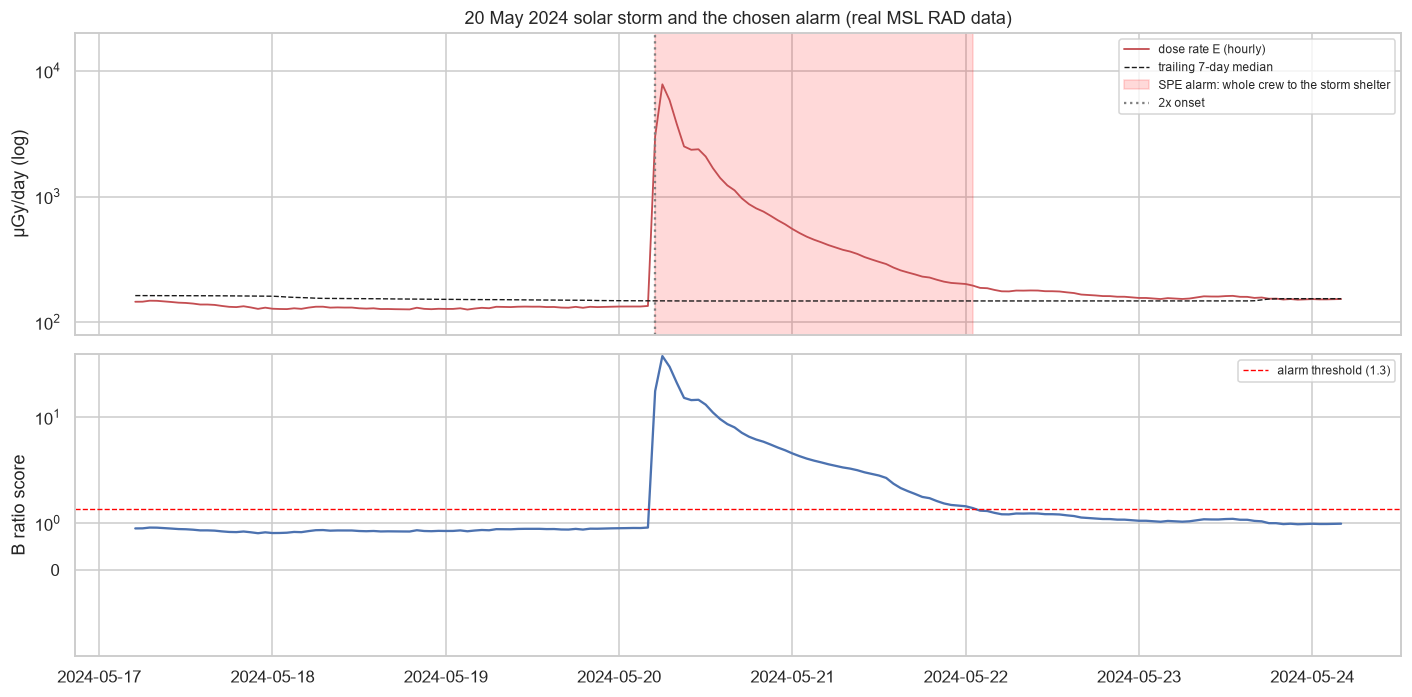

In [10]:
chosen = ok.sort_values(SORT, ascending=ASC).iloc[0]
plan = ok[(ok.method == "robust_z")].sort_values(SORT, ascending=ASC).iloc[0]
print("chosen:", chosen.model, "| deseasonalized:", bool(chosen.deseasonalized), "| thr", chosen.thr, "| hold", chosen.hold_hours, "h")
full_chosen = scores_for(x, local_hour, bool(chosen.deseasonalized))[chosen.method]
alert = rad.persistent(np.nan_to_num(full_chosen, nan=-np.inf) > chosen.thr, int(chosen.hold_hours))
w = slice(onset - 72, onset + 96)
fig, axes = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)
axes[0].plot(T[w], x[w], color="#c44e52", lw=1.2, label="dose rate E (hourly)")
axes[0].plot(T[w], rad.trailing_baseline(x)[0][w], color="k", ls="--", lw=0.9, label="trailing 7-day median")
axes[0].fill_between(T[w], 1, 1e5, where=alert[w], color="red", alpha=0.15, label="SPE alarm: whole crew to the storm shelter")
axes[0].axvline(T[onset], color="grey", ls=":", label="2x onset")
axes[0].set(yscale="log", ylim=(80, 2e4), ylabel="µGy/day (log)", title="20 May 2024 solar storm and the chosen alarm (real MSL RAD data)")
axes[0].legend(fontsize=8, loc="upper right")
axes[1].plot(T[w], full_chosen[w], color="#4c72b0")
axes[1].axhline(chosen.thr, color="red", ls="--", lw=0.9, label=f"alarm threshold ({chosen.thr:g})")
axes[1].set(yscale="symlog", ylabel=f"{chosen.model} score"); axes[1].legend(fontsize=8)
savefig("05_may2024_alarm");
first = int(np.flatnonzero(alert[onset - 24: onset + 48])[0]) + onset - 24
print("first alarm hour:", T[first], "| dose rate that hour: %.0f (%.1fx quiet)" % (x[first], x[first] / base), "| alarm lasted", int(alert[onset - 24: last_high + 48].sum()), "hours")
hours = np.flatnonzero(alert & ~excluded)
starts = hours[np.concatenate([[True], np.diff(hours) > 24])] if len(hours) else hours
print("alarm events outside the storm (date, E vs baseline at the first alarm hour, confirmed by detector B):")
print([(str(T[s].date()), round(float(x[s] / rad.trailing_baseline(x)[0][s]), 2), confirmed_by_b(int(s))) for s in starts])
print("alarm hours per year:", {int(y): int(alert[T.year == y].sum()) for y in sorted(set(T.year))})

In [11]:
# What the alarm is worth: with hourly means, the alarm for an hour is known when that hour ends.
known_at = first + 1
excess = np.nan_to_num(x[onset: last_high + 1] - base, nan=0.0).clip(min=0)
after = np.nan_to_num(x[known_at: last_high + 1] - base, nan=0.0).clip(min=0)
print("alarm known at %s; the storm's peak observation was at 06:15 UTC" % T[known_at])
print("share of the storm's extra dose that arrived after the alarm: %.0f %%" % (100 * after.sum() / excess.sum()))

alarm known at 2024-05-20 06:00:00; the storm's peak observation was at 06:15 UTC
share of the storm's extra dose that arrived after the alarm: 93 %


In [12]:
config_path = MODELS / "engine_config.json"
config = json.loads(config_path.read_text()) if config_path.exists() else {}
config["radiation"] = {
    "source_notebook": "05_radiation_models",
    "dose_counter": {"quality_factor": Q, "budget_msv": BUDGET_MSV, "yellow_share": rad.YELLOW_SHARE, "red_share": rad.RED_SHARE,
                     "msv_per_day": {"iss": round(float(rates.loc["ISS", "dose equivalent (mSv/day)"]), 3),
                                     "mars_transit": TRANSIT_MSV_PER_DAY,
                                     "mars_surface": round(float(rates.loc["Mars surface", "dose equivalent (mSv/day)"]), 3)}},
    "spe_detector": {"method": chosen.method, "signal": "dose_e hourly mean (uGy/day)", "baseline_window_hours": rad.WEEK_HOURS,
                     "deseasonalize": bool(chosen.deseasonalized), "threshold": float(chosen.thr), "hold_hours": int(chosen.hold_hours),
                     "may2024_delay_hours": float(chosen.may2024_delay_h), "other_alarm_events_in_record": int(chosen.other_events),
                     "of_which_confirmed_by_detector_b": int(chosen.confirmed_by_detector_b), "false_alarms_in_record": int(chosen.false_alarms),
                     "record_months": round(float(months), 1),
                     "caught_by_peak_size": {f"{p:g}x": float(chosen[f"caught_{p:g}x"]) for p in PEAKS}},
    "action": "SPE in progress: whole crew to the storm shelter",
}
config_path.write_text(json.dumps(config, indent=2))
print(json.dumps(config["radiation"], indent=2))
print("\nteam's plan (A robust z) at its best setting:", plan[show[2:]].round(2).to_dict())

{
  "source_notebook": "05_radiation_models",
  "dose_counter": {
    "quality_factor": 3.0,
    "budget_msv": 600.0,
    "yellow_share": 0.8,
    "red_share": 1.0,
    "msv_per_day": {
      "iss": 0.875,
      "mars_transit": 1.84,
      "mars_surface": 0.492
    }
  },
  "spe_detector": {
    "method": "ratio",
    "signal": "dose_e hourly mean (uGy/day)",
    "baseline_window_hours": 168,
    "deseasonalize": false,
    "threshold": 1.3,
    "hold_hours": 1,
    "may2024_delay_hours": 0.0,
    "other_alarm_events_in_record": 6,
    "of_which_confirmed_by_detector_b": 6,
    "false_alarms_in_record": 0,
    "record_months": 34.7,
    "caught_by_peak_size": {
      "1.5x": 1.0,
      "2x": 1.0,
      "3x": 1.0,
      "5x": 1.0
    }
  },
  "action": "SPE in progress: whole crew to the storm shelter"
}

team's plan (A robust z) at its best setting: {'thr': 6.0, 'hold_hours': 1, 'may2024_delay_h': 0.0, 'other_events': 11, 'confirmed_by_detector_b': 11, 'false_alarms': 0, 'caught_1.5x':

## Decision

### Dose counter (deterministic)
`dose equivalent (mSv) = Σ daily absorbed dose (mGy) × Q`, with **Q = 3.0** (Hassler et al. 2014), against a **600 mSv** budget
(NASA-STD-3001 career limit, the value the v0 engine already uses). **YELLOW at 80 %, RED at 100 %.** A day without data counts at the recent median, never as zero.

| setting | rate | source | YELLOW on day | RED on day |
|---|---|---|---|---|
| ISS | 0.29 mGy/day → 0.88 mSv/day | real OSDR EDA dosimetry × Q | 549 | 686 |
| Mars transit | 1.84 mSv/day | published constant (Zeitlin et al. 2013) | 261 | 326 |
| Mars surface | 0.16 mGy/day → 0.49 mSv/day | real MSL RAD detector E × Q | 976 | 1,221 |

A 180-day outbound + 500-day surface + 180-day return mission totals **908 mSv, 151 % of the budget**: YELLOW on mission day 483 and RED on day 693, during the return leg.
The May 2024 storm added 5.2 mSv on the surface, 0.9 % of the budget. On the surface a storm matters as an acute event, not for the budget; in transit, without an atmosphere, it would be far larger.

### Storm (SPE) alarm
**Chosen: B, ratio of the hourly dose rate to the trailing 7-day median, alarm at 1.3×, on the raw hourly series.**
Alert sentence: *"Radiation dose rate is N times the 7-day normal for H hours. SPE in progress: whole crew to the storm shelter."*

| model | setting | May 2024: hours after onset | other alarm events in 35 months | confirmed real by detector B | false alarms | planted storms caught (1.5× / 2× / 3× / 5×) |
|---|---|---|---|---|---|---|
| **B ratio (chosen)** | ≥ 1.3× | 0 | 6 | 6 | **0** | 100 / 100 / 100 / 100 % |
| E change point (PELT) | ≥ 20 noise SDs | 0 | 6 | 6 | 0 | 100 / 100 / 100 / 100 % |
| A robust z (team's plan) | z > 6 | 0 | 11 | 11 | 0 | 100 / 100 / 100 / 100 % |
| D EWMA on log dose | > 4, deseasonalized | 0 | 10 | 10 | 0 | 97 / 100 / 100 / 100 % |
| C CUSUM on log dose | > 160 | 7 | 5 | 4 | 1 | 9–47 / 76–79 / 94 / 97–98 % |

**Why B:** A, B and E all catch the May 2024 storm in its first hour, catch every planted storm down to 1.5× the quiet level, and raise no unconfirmed alarm in 35 months.
B is the simplest, its sentence needs no statistics ("1.6 times normal"), and it calls the crew to the shelter for 6 smaller events where A calls for 11. The simple model wins the tie.

**The team's plan (A, robust z) also works**, but only at z > 6, not at the usual 3: quiet hours scatter by about 3 % with heavy tails, so z > 4 gives 9 unconfirmed alarms.
It is kept as the fallback.

**Rejected:** C CUSUM (7 hours late on the real storm and 1–54 false alarms: accumulating evidence is the wrong tool for an abrupt event);
D EWMA (no better than B and needs more tuning); E change point (equal to B, about 100 ms per call and harder to explain; it needed a 15 % pre-filter to be fast enough).

**Checks the plan asked for**
- **20 May 2024 is caught**, in the hour the dose rate first passed twice the quiet level (05:00–06:00 UTC, 20× quiet in that hour). With hourly means the alarm is known at 06:00,
  15 minutes before the peak observation, and **93 % of the storm's extra dose arrived after the alarm**. That is the dose a shelter can avoid.
  The delay is 0 hours rather than a lead time: the storm rose from quiet to 20× within one hour, so nothing in RAD's own data announces it earlier.
  (The Forbush decrease of the three days before is a hint, not a usable alarm.)
- **Diurnal cycle: handled by testing, and removing it does not help.** Quiet-hour scatter is 3.16 % raw and 3.17 % with the cycle removed, and every model had the same or more false alarms after removal.
  A 3.4 % daily cycle is far below a 30 % alarm level. The chosen detector uses the raw series; `deseasonalize` stays in the library.
- **Slow solar-cycle drift raises no alarms.** The quiet level rose 12 % from 2025 to 2026 and the chosen detector did not alarm once in 2026. The 7-day median absorbs it.

**What needs a team decision (also raised in chat)**
- **Six smaller real events in 35 months (1.4–1.7× normal) also trigger "whole crew to the shelter".** They are real rises (the independent silicon detector confirms each), but small.
  A two-level alarm would fit better: YELLOW "radiation elevated" from 1.3×, RED "shelter" from 2× (at 2× there is 1 other event in 35 months and May 2024 is still caught in the first hour,
  but only half of the planted 2× storms are). The plan specifies a single shelter alarm, so that is what is written to `engine_config.json`.
- **Q = 3.0 was measured on the Mars surface.** Applying it to ISS dosimetry probably overstates the ISS dose equivalent; the ISS line should be read as conservative.

**Known limits:** one large storm in the record, so sensitivity comes from scaled copies of that one storm's shape. "False alarm" means "not confirmed by RAD's second detector",
which shares the instrument's electronics. The surface sits under the Martian atmosphere; a transit alarm would see faster and harder events.